# HMRW Edge-Bias Study

Single synthetic hypergraph

Fixed values:
- `p = 1`, `q = 1`
- `num_walks = 10` (walks per node)
- `walk_length = 10`

For each `(p_edge, q_edge)` pair, run 5 repeats and report mean Micro/Macro-F1.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

from src.synthetic import generate_dataset
from src.utils import hmrw_embeddings

In [8]:
def evaluate_embeddings(X, y, seed=42, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    clf = LogisticRegression(max_iter=3000)
    scores = cross_validate(
        clf,
        X,
        y,
        cv=cv,
        scoring={"micro_f1": "f1_micro", "macro_f1": "f1_macro"},
        n_jobs=-1,
        return_train_score=False,
    )
    return float(np.mean(scores["test_micro_f1"])), float(np.mean(scores["test_macro_f1"]))

In [9]:
# Generate one synthetic dataset
data_seed = 777
sample = generate_dataset(
    n=1000,
    avg_degree=12,
    num_communities=3,
    intra_strength=0.8,
    avg_edge_size=4,
    max_hyperedge_size=10,
    seed=data_seed,
)
H = sample["H"]
nodes = sorted(H.get_nodes())
y = np.array([sample["g1"][u] for u in nodes])

print(f"Generated H with {len(nodes)} nodes and {len(H.get_edges())} hyperedges")

generate_dataset params -> n=1000, avg_degree=12, num_communities=3, intra_strength=0.8, avg_edge_size=4, max_hyperedge_size=10, seed=777
Generated H with 946 nodes and 1821 hyperedges


In [15]:
# Fixed params requested
fixed_params = dict(
    p=1.0,
    q=1.0,
    num_walks=10,
    walk_length=10,
    window=5,
    dim=64,
    workers=1,
)
grid = [0.5, 1.0, 2.0, 4.0]
n_repeats = 10
base_seed = 42

In [5]:
rows = []

for p_edge in grid:
    for q_edge in grid:
        micro_runs = []
        macro_runs = []
        for rep in range(n_repeats):
            seed = base_seed + rep
            X = hmrw_embeddings(
                H,
                p_edge=p_edge,
                q_edge=q_edge,
                seed=seed,
                **fixed_params,
            )
            micro, macro = evaluate_embeddings(X, y, seed=seed)
            micro_runs.append(micro)
            macro_runs.append(macro)

        rows.append(
            {
                "p_edge": p_edge,
                "q_edge": q_edge,
                "micro_f1_mean": float(np.mean(micro_runs)),
                "micro_f1_std": float(np.std(micro_runs)),
                "macro_f1_mean": float(np.mean(macro_runs)),
                "macro_f1_std": float(np.std(macro_runs)),
            }
        )

results = pd.DataFrame(rows).sort_values("macro_f1_mean", ascending=False)
results

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

,p_edge,q_edge,micro_f1_mean,micro_f1_std,macro_f1_mean,macro_f1_std
15,4.0,4.0,0.339689,0.012494,0.338386,0.012660
7,1.0,4.0,0.339482,0.011953,0.338122,0.011733
9,2.0,1.0,0.338653,0.008948,0.337506,0.008093
4,1.0,0.5,0.339067,0.022278,0.337003,0.021870
12,4.0,0.5,0.334922,0.023752,0.333452,0.023479
1,0.5,1.0,0.333264,0.008610,0.331708,0.008632
13,4.0,1.0,0.332642,0.016735,0.331546,0.016245
6,1.0,2.0,0.332435,0.012562,0.331207,0.012376
3,0.5,4.0,0.332642,0.017315,0.331025,0.017534
11,2.0,4.0,0.330777,0.014047,0.329008,0.014314


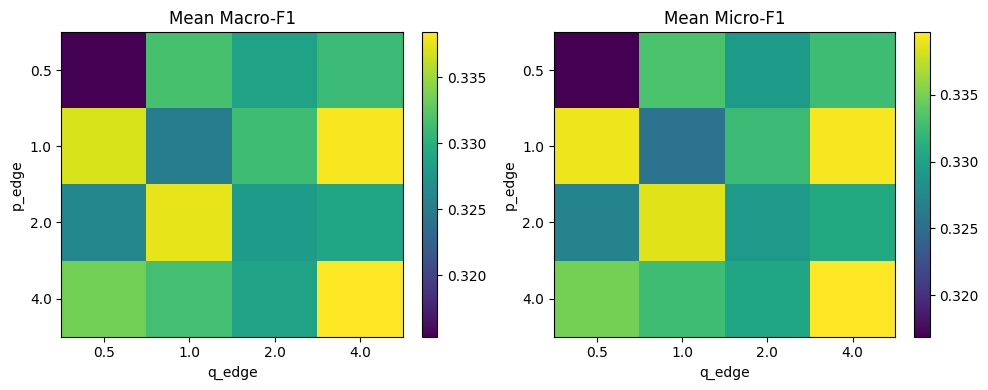

In [6]:
# Heatmaps for mean Micro/Macro-F1
macro_heat = results.pivot(index="p_edge", columns="q_edge", values="macro_f1_mean").sort_index().sort_index(axis=1)
micro_heat = results.pivot(index="p_edge", columns="q_edge", values="micro_f1_mean").sort_index().sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(macro_heat.values, aspect="auto")
axes[0].set_title("Mean Macro-F1")
axes[0].set_xlabel("q_edge")
axes[0].set_ylabel("p_edge")
axes[0].set_xticks(range(len(macro_heat.columns)), macro_heat.columns)
axes[0].set_yticks(range(len(macro_heat.index)), macro_heat.index)
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(micro_heat.values, aspect="auto")
axes[1].set_title("Mean Micro-F1")
axes[1].set_xlabel("q_edge")
axes[1].set_ylabel("p_edge")
axes[1].set_xticks(range(len(micro_heat.columns)), micro_heat.columns)
axes[1].set_yticks(range(len(micro_heat.index)), micro_heat.index)
fig.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

In [ ]:
results.to_csv("hmrw_pedge_qedge_sweep.csv", index=False)
print("Saved: hmrw_pedge_qedge_sweep.csv")

In [16]:
# Sweep A/B for plots like the reference image:
# - Macro-F1 vs number of walks per node r
# - Macro-F1 vs walk length l
# Keep p, q fixed at 1; use best (p_edge, q_edge) found above.

best_row = results.sort_values("macro_f1_mean", ascending=False).iloc[0]
best_p_edge = 1.0
best_q_edge = 1.0

walks_grid = [5, 10, 15, 20, 25, 30]
length_grid = [20, 40, 60, 80, 100]

rows_walks = []
for r_walks in walks_grid:
    macro_runs = []
    for rep in range(n_repeats):
        seed = base_seed + rep
        X = hmrw_embeddings(
            H,
            p=1.0,
            q=1.0,
            p_edge=best_p_edge,
            q_edge=best_q_edge,
            num_walks=r_walks,
            walk_length=10,
            window=5,
            dim=64,
            workers=1,
            seed=seed,
        )
        _, macro = evaluate_embeddings(X, y, seed=seed)
        macro_runs.append(macro)
    rows_walks.append({"num_walks": r_walks, "macro_f1_mean": float(np.mean(macro_runs))})

rows_len = []
for l_walk in length_grid:
    macro_runs = []
    for rep in range(n_repeats):
        seed = base_seed + rep
        X = hmrw_embeddings(
            H,
            p=1.0,
            q=1.0,
            p_edge=best_p_edge,
            q_edge=best_q_edge,
            num_walks=10,
            walk_length=l_walk,
            window=5,
            dim=64,
            workers=1,
            seed=seed,
        )
        _, macro = evaluate_embeddings(X, y, seed=seed)
        macro_runs.append(macro)
    rows_len.append({"walk_length": l_walk, "macro_f1_mean": float(np.mean(macro_runs))})

walks_curve = pd.DataFrame(rows_walks)
length_curve = pd.DataFrame(rows_len)

print(f"Using p_edge={best_p_edge}, q_edge={best_q_edge} for these curves")
walks_curve, length_curve

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

Using p_edge=1.0, q_edge=1.0 for these curves


(   num_walks  macro_f1_mean
 0          5       0.334852
 1         10       0.343458
 2         15       0.338982
 3         20       0.341093
 4         25       0.345715
 5         30       0.345553,
    walk_length  macro_f1_mean
 0           20       0.337075
 1           40       0.343337
 2           60       0.334919
 3           80       0.332319
 4          100       0.344106)

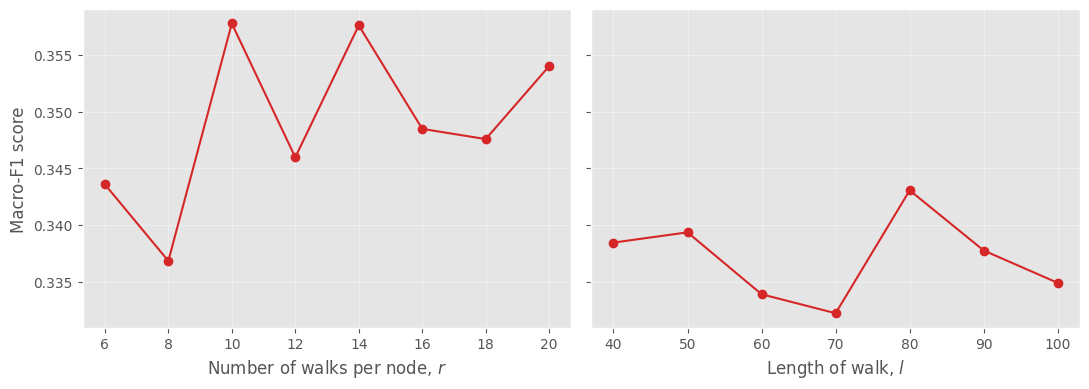

In [11]:
# Two-panel plot (style like your screenshot)
plt.style.use("ggplot")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].plot(walks_curve["num_walks"], walks_curve["macro_f1_mean"], marker="o", color="tab:red")
axes[0].set_xlabel(r"Number of walks per node, $r$")
axes[0].set_ylabel("Macro-F1 score")

axes[1].plot(length_curve["walk_length"], length_curve["macro_f1_mean"], marker="o", color="tab:red")
axes[1].set_xlabel(r"Length of walk, $l$")

for ax in axes:
    ax.grid(True, alpha=0.35)

plt.tight_layout()
plt.show()